# Galaxy rotation orbits: graph + simulation
Set the parameters once, then run **either** the graph cell or the simulation cell (or both). Both read the same `params`, `r0`, `rdot0`, `phi0`, `phi_max`.

Run the parameter cell again after you change it.

## Parameters

In [20]:
import numpy as np

# --- 07: Rosebud / petal orbit (your values, restored) ---
#   These were YOUR edits from 2026-11-12 (rs=10, c=2); I only restored them.
#   Variable mass: petals diving to r ≈ 11 from 3000; over 2π the petal tips sit at 0°, 76°, 152°, 228°, 304°.
#   Schwarzschild: fat ellipse, ~300 – 3000, turning slowly.
# params = dict(rs=10, L0=19.2, E0=10.0, L1=38.4, E1=10.109987141435937, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
# r0, rdot0 = 3000.0, 0.0          # initial r and dr/dtau
# phi0, phi_max = 0.0, 6*np.pi

# --- 08: Near-circular, close to the body (~8 rs) ---
#   Both set to circle at r = 80, started 10% out.
#   Variable mass: r ≈ 71.9 – 88, ≈ +34° per orbit.
#   Schwarzschild:  r ≈ 73.2 – 88, ≈ +96° per orbit.
# params = dict(rs=10, L0=19.2, E0=10.0, L1=22.188007849009164, E1=10.015446531771273, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
# r0, rdot0 = 88.0, 0.0          # initial r and dr/dtau
# phi0, phi_max = 0.0, 6*np.pi

# --- 09: A bit less circular ---
#   Only r0 changed from 08.
#   Variable mass: r ≈ 59.5 – 100 (ratio 1.68), ≈ +37° per orbit.
#   Schwarzschild:  r ≈ 66.2 – 100 (ratio 1.51), ≈ +96° per orbit.
#   (r0 = 110 gives blue 49–110, red 62–110.)
# params = dict(rs=10, L0=19.2, E0=10.0, L1=22.188007849009164, E1=10.015446531771273, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
# r0, rdot0 = 100.0, 0.0          # initial r and dr/dtau
# phi0, phi_max = 0.0, 6*np.pi

# --- 10: Higher eccentricity ---
#   Only r0 changed from 08.
#   Variable mass: r ≈ 21.1 – 150, e ≈ 0.75, ≈ +29° per orbit.
#   Schwarzschild:  r ≈ 52.8 – 150, e ≈ 0.48, ≈ +100° per orbit.
#   Other r0 checked: 130 (your value) blue e≈0.62 +45°, red e≈0.39 +98°;
#   180 blue e≈0.83 −9°; 220 blue e≈0.87 −48°.
params = dict(rs=10, L0=19.2, E0=10.0, L1=22.188007849009164, E1=10.015446531771273, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
r0, rdot0 = 150.0, 0.0          # initial r and dr/dtau
phi0, phi_max = 0.0, 6*np.pi

# --- 11: Matched orbits: same closest/farthest points (CURRENT) ---
#   Both orbits: r ≈ 46.0 – 150, e ≈ 0.53, ≈ +116.5° per orbit; apsides at almost the same angles
#   (closest 238° vs 241°, farthest 477° vs 476°), but the paths between differ (r'² term).
#   This is what is in galaxy-rotation-orbits.ipynb and galaxy_rotation_orbits_sim.py now (sim script set 2026-11-14).
# params = dict(rs=10, L0=19.2, E0=10.0, L1=21.428459297547853, E1=10.009041703577916, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
# r0, rdot0 = 150.0, .0          # initial r and dr/dtau
# phi0, phi_max = 0.0, 6*np.pi

# --- galaxy_rotation_orbits_sim.py (original sim preset, not in orbit-parameters/) ---
# params = dict(rs=.1, L0=19.2, E0=10.0, L1=20., E1=9.1, c=1)
# r0, rdot0 = 20.0, .02
# phi0, phi_max = 0.0, 8*np.pi

# ---------------------------------------------------------------------------
# Active parameters (= preset 11): shared by the graph cell and the simulation cell
# ---------------------------------------------------------------------------
# params = dict(rs=10, L0=19.2, E0=10.0, L1=21.428459297547853, E1=10.009041703577916, c=2)   # L0,E0: m(r);  L1,E1: geodesic / phidot
# r0, rdot0 = 150.0, .0          # initial r and dr/dtau
# phi0, phi_max = 0.0, 6*np.pi


## Graph: $r(\phi)$ vs Schwarzschild (from `galaxy-rotation-orbits.ipynb`)

initial dr/dphi = -0.0
finished
finished


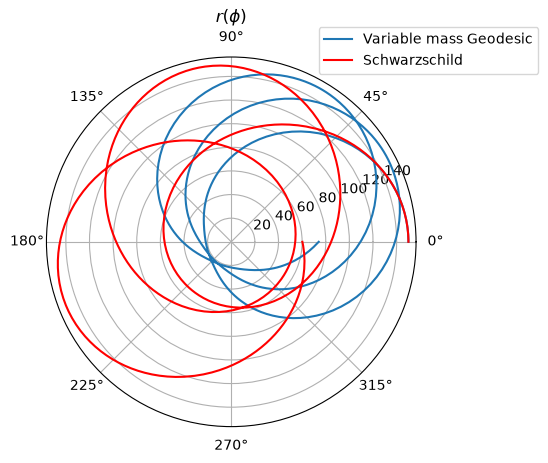

In [21]:
# ===== galaxy-rotation-orbits.ipynb: symbolic setup, RK45 in phi, Schwarzschild comparison, plot =====

# uses params, r0, rdot0, phi0, phi_max from the parameter cell

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import RK45

# symbols
r, tau, rs = sp.symbols(r'r \tau r_s', positive=True)
E0, L0 = sp.symbols('E_0 L_0', positive=True)   # constants in m(r)
E1, L1 = sp.symbols('E_1 L_1', positive=True)   # constants in the geodesic; L1 also in phidot = -L1/(m r^2)
c = sp.Symbol('c')                              # integration constant of m(r)
rd, rdd = sp.symbols('rdot rddot', real=True)   # dr/dtau, d²r/dtau²
rp, rpp = sp.symbols(r'\frac{\partial\ r}{\partial\ \phi} \frac{\partial^2r}{\partial\phi^2}', real=True)  # dr/dphi, d²r/dphi²
m = sp.Function('m')(r)
m_s = sp.Symbol('m', positive=True)             # plain symbol for m, used in the r̈ expression

# 1. field equation

N = 1 - rs/r
D = L0**2 - rs*r*E0**2
eq = sp.Eq(0, rdd
              + rd**2 * rs/(2*N*r**2)
              + r**3*rd**2/D
              + (r**3 - r**2*rs)/D * ((L1**2 - L0**2)/r**3 - rs*(E1**2 - E0**2)/r**2))

# 2. m(r)

m_sol = sp.sqrt(c + rs*E0**2/r - L0**2/r**2)

dm_dr = (L0**2/r**3 - rs*E0**2/(2*r**2))/m_s    # ∂m/∂r in terms of m

# 3. orbit equation in phi

rd_phi  = -L1*rp/(m_s*r**2)
rdd_phi = L1**2/(m_s**2*r**4) * (rpp - (2/r + dm_dr/m_s)*rp**2)   # r̈ from the geodesic notebook

# d²r/dphi² as given above, with m -> m_sol and N = 1 - rs/r
rpp_expr = (m_sol*rs/(2*N*r**2) * rp**2
            + m_sol*N*((1 - L0**2/L1**2)*r - rs*(E1**2 - E0**2)*r**2/(2*L1**2)))
ode_2 = sp.Eq(rpp, rpp_expr)

# 4. numerical integration

# numerical functions of (r, dr/dphi, parameters)
rpp_func = sp.lambdify((r, rp, rs, L0, E0, L1, E1, c), rpp_expr, 'numpy')
m_func   = sp.lambdify((r, rs, L0, E0, c), m_sol, 'numpy')

# convert the initial dr/dtau into dr/dphi:  dr/dphi = -rdot * m r^2 / L1
rp0 = -rdot0 * m_func(r0, params['rs'], params['L0'], params['E0'], params['c']) * r0**2 / params['L1']
print(f'initial dr/dphi = {rp0}')

# First-order system: y = [r, dr/dphi]  ->  dy/dphi = [dr/dphi, d²r/dphi²]
def system(phi, y):
    return [y[1], rpp_func(y[0], y[1], params['rs'], params['L0'], params['E0'],
                           params['L1'], params['E1'], params['c'])]

solver = RK45(system, phi0, [r0, rp0], t_bound=phi_max, max_step=0.1, rtol=1e-9, atol=1e-12)

phis, ys = [solver.t], [solver.y.copy()]
while solver.status == 'running':
    solver.step()
    phis.append(solver.t)
    ys.append(solver.y.copy())

phi = np.array(phis)
r_sol, rp_sol = np.array(ys).T
print(solver.status)

# Standard Schwarzschild orbit with the same rs, L1, r0, rdot0 (m = 1), same RK45 settings.
# Binet form u'' + u = rs/(2 L^2) + (3/2) rs u^2 with u = 1/r, rewritten for r(phi):
#   d²r/dphi² = 2 (dr/dphi)^2 / r + r - rs r^2 / (2 L1^2) - 3 rs / 2
# (E1 does not appear: it is fixed by r0, rdot0 and L1.)
rp0_s = -rdot0 * r0**2 / params['L1']          # dr/dphi = -rdot r^2 / L1  (m = 1)

def system_s(phi, y):
    r_, rp_ = y
    return [rp_, 2*rp_**2/r_ + r_ - params['rs']*r_**2/(2*params['L1']**2) - 1.5*params['rs']]

solver_s = RK45(system_s, phi0, [r0, rp0_s], t_bound=phi_max, max_step=0.1, rtol=1e-9, atol=1e-12)

phis_s, ys_s = [solver_s.t], [solver_s.y.copy()]
while solver_s.status == 'running':
    solver_s.step()
    phis_s.append(solver_s.t)
    ys_s.append(solver_s.y.copy())

phi_s = np.array(phis_s)
r_sol_s, rp_sol_s = np.array(ys_s).T
print(solver_s.status)

# plot

# orbit in the equatorial plane (theta = pi/2), integrated directly in phi
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(phi, r_sol, label='Variable mass Geodesic')
ax.plot(phi_s, r_sol_s, color='red', label='Schwarzschild')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
ax.set_title(r'$r(\phi)$')
plt.show()


## Simulation: pygame animation, variable mass (blue) vs Schwarzschild (red) (from `galaxy_rotation_orbits_sim.py`)

In [22]:
# ===== galaxy_rotation_orbits_sim.py: pygame animation =====
# Blue: variable mass geodesic (notebook d²r/dφ²). Red: Schwarzschild, same rs, L1, r0, rdot0.
# uses params, r0, rdot0, phi0, phi_max from the parameter cell.
# Opens a pygame window; the cell runs until you close it (ESC / Q).
# Controls: SPACE pause, UP/DOWN speed, +/- zoom, R restart, ESC/Q quit

import numpy as np
import sympy as sp
import pygame
from scipy.integrate import RK45


# Parameters and initial conditions come from the parameter cell
# ---------------------------------------------------------------------------
# Symbolic equation of motion (same as the notebook, cell 11)
# ---------------------------------------------------------------------------
r, rs = sp.symbols('r r_s', positive=True)
E0, L0, E1, L1 = sp.symbols('E_0 L_0 E_1 L_1', positive=True)
c = sp.Symbol('c')
rp, rpp = sp.symbols('rp rpp', real=True)       # dr/dphi, d²r/dphi²

N = 1 - rs/r

# m(r)
m_sol = sp.sqrt(c + rs*E0**2/r - L0**2/r**2)

# d²r/dphi² (same as the notebook), with m -> m_sol and N = 1 - rs/r
rpp_expr = (m_sol*rs/(2*N*r**2) * rp**2
            + m_sol*N*((1 - L0**2/L1**2)*r - rs*(E1**2 - E0**2)*r**2/(2*L1**2)))
sp.pprint(sp.Eq(rpp, rpp_expr))

rpp_func = sp.lambdify((r, rp, rs, L0, E0, L1, E1, c), rpp_expr, 'numpy')
m_func   = sp.lambdify((r, rs, L0, E0, c), m_sol, 'numpy')
# ---------------------------------------------------------------------------

# m(r) is only real where m^2 = c + rs E0^2/r - L0^2/r^2 > 0
m2_0 = params['c'] + params['rs']*params['E0']**2/r0 - params['L0']**2/r0**2
if m2_0 <= 0:
    raise SystemExit(f'm(r0)^2 = {m2_0:.4g} <= 0, so m(r0) is imaginary: choose r0, c, E0, L0 '
                     f'with c*r0^2 + rs*E0^2*r0 > L0^2')

# initial dr/dtau -> dr/dphi:  dr/dphi = -rdot * m r^2 / L1
rp0 = -rdot0 * m_func(r0, params['rs'], params['L0'], params['E0'], params['c']) * r0**2 / params['L1']


def system(phi, y):
    return [y[1], rpp_func(y[0], y[1], params['rs'], params['L0'], params['E0'],
                           params['L1'], params['E1'], params['c'])]


# Standard Schwarzschild orbit with the same rs, L1, r0, rdot0 (m = 1), as in the notebook.
# Binet form u'' + u = rs/(2 L^2) + (3/2) rs u^2 with u = 1/r, rewritten for r(phi):
#   d²r/dphi² = 2 (dr/dphi)^2 / r + r - rs r^2 / (2 L1^2) - 3 rs / 2
rp0_s = -rdot0 * r0**2 / params['L1']          # dr/dphi = -rdot r^2 / L1  (m = 1)


def system_s(phi, y):
    r_, rp_ = y
    return [rp_, 2*rp_**2/r_ + r_ - params['rs']*r_**2/(2*params['L1']**2) - 1.5*params['rs']]


def new_solver(f, y0):
    return RK45(f, phi0, y0, t_bound=phi_max, max_step=0.05, rtol=1e-9, atol=1e-12)


# ---------------------------------------------------------------------------
# Pygame setup
# ---------------------------------------------------------------------------
width, height = 800, 800
center_x = width // 2
center_y = height // 2

BG = (10, 10, 20)
GRID = (40, 40, 60)
BLUE = (80, 160, 255)        # variable mass geodesic
RED = (255, 70, 70)           # Schwarzschild
BLUE_TRAIL = (50, 100, 170)
RED_TRAIL = (170, 50, 50)
HORIZON = (200, 60, 60)
TEXT = (220, 220, 220)

MONITOR = 1  # which display to open on (0 = primary); falls back to 0 if not connected

pygame.init()
monitor = MONITOR if MONITOR < pygame.display.get_num_displays() else 0
screen = pygame.display.set_mode((width, height), display=monitor)
pygame.display.set_caption('r(phi) orbits: variable mass (blue) vs Schwarzschild (red)')
clock = pygame.time.Clock()
font = pygame.font.SysFont('menlo', 16)

# pixels per unit of r; auto-fit so the largest r reached so far fills the window
fit_radius = 0.9 * min(center_x, center_y)
base_scale = fit_radius / abs(r0)
zoom = 1.0  # manual zoom on top of the auto-fit


def to_screen(r_val, phi_val):
    s = base_scale * zoom
    return (center_x + r_val * np.cos(phi_val) * s,
            center_y - r_val * np.sin(phi_val) * s)


def draw_grid():
    s = base_scale * zoom
    # rings at a 1-2-5 step in r so they stay ~40 px apart at any scale
    raw = 40 / s
    mag = 10 ** np.floor(np.log10(raw))
    step = next(k * mag for k in (1, 2, 5, 10) if k * mag >= raw)
    max_r = np.hypot(center_x, center_y) / s
    for ring in np.arange(step, max_r + step, step):
        pygame.draw.circle(screen, GRID, (center_x, center_y), int(ring * s), 1)
    for k in range(8):
        a = k * np.pi / 4
        pygame.draw.line(screen, GRID, (center_x, center_y),
                         (center_x + 2 * width * np.cos(a), center_y - 2 * width * np.sin(a)), 1)
    pygame.draw.circle(screen, HORIZON, (center_x, center_y), max(2, int(params['rs'] * s)))


class Orbit:
    def __init__(self, name, f, y0, body, trail):
        self.name, self.f, self.y0, self.body, self.trail = name, f, y0, body, trail
        self.reset()

    def reset(self):
        self.solver = new_solver(self.f, self.y0)
        self.phis, self.ys = [self.solver.t], [self.solver.y.copy()]
        self.fail_msg = ''
        self.broken = False   # True once this orbit can't continue; the other one keeps going

    @property
    def done(self):
        return self.broken or self.solver.status != 'running'

    def _break(self, msg):
        self.broken, self.fail_msg = True, msg

    def advance(self, phi_target):
        """Step the integrator past phi_target; return (phi, r, dr/dphi) to draw.

        Any failure (solver failure, exception, NaN/inf, r <= 0) stops only this
        orbit, which stays frozen at its last good point.
        """
        sv = self.solver
        while not self.broken and sv.status == 'running' and sv.t < phi_target:
            try:
                msg = sv.step()
            except Exception as e:
                self._break(f'{type(e).__name__}: {e}')
                break
            if sv.status == 'failed':
                self._break(msg or 'step failed')
                break
            if not np.all(np.isfinite(sv.y)):
                self._break(f'non-finite state at phi = {sv.t:.4f}')
                break
            if sv.y[0] <= 0:
                self._break(f'r <= 0 at phi = {sv.t:.4f}')
                break
            self.phis.append(sv.t)
            self.ys.append(sv.y.copy())
        # interpolate inside the last RK45 step (only while the orbit is healthy)
        if (not self.broken and sv.step_size is not None and sv.t_old is not None
                and sv.t_old <= phi_target <= sv.t):
            try:
                r_now, rp_now = sv.dense_output()(phi_target)
                if np.isfinite(r_now) and np.isfinite(rp_now):
                    return phi_target, r_now, rp_now
            except Exception:
                pass
        r_now, rp_now = self.ys[-1]
        return min(phi_target, self.phis[-1]), r_now, rp_now

    def status_line(self, phi_now):
        if self.broken:
            return f'{self.name}: stopped ({self.fail_msg})'
        if self.solver.status == 'finished' and phi_now >= phi_max:
            return f'{self.name}: finished'
        return None


orbits = [
    Orbit('variable mass', system, [r0, rp0], BLUE, BLUE_TRAIL),
    Orbit('Schwarzschild', system_s, [r0, rp0_s], RED, RED_TRAIL),
]


def reset():
    global base_scale, r_max
    for o in orbits:
        o.reset()
    r_max = abs(r0)
    base_scale = fit_radius / r_max
    return phi0


phi_now = reset()
speed = 1.0  # radians of phi per second
paused = False
running = True

while running:
    dt = clock.tick(60) / 1000

    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False
        elif event.type == pygame.KEYDOWN:
            if event.key in (pygame.K_ESCAPE, pygame.K_q):
                running = False
            elif event.key == pygame.K_SPACE:
                paused = not paused
            elif event.key == pygame.K_UP:
                speed *= 1.5
            elif event.key == pygame.K_DOWN:
                speed /= 1.5
            elif event.key in (pygame.K_EQUALS, pygame.K_PLUS, pygame.K_KP_PLUS):
                zoom *= 1.25
            elif event.key in (pygame.K_MINUS, pygame.K_KP_MINUS):
                zoom /= 1.25
            elif event.key == pygame.K_r:
                phi_now = reset()

    if not paused:
        phi_now = min(phi_now + speed * dt, phi_max)

    # Advance both integrators to the displayed phi (each stops on its own if it fails)
    states = [o.advance(phi_now) for o in orbits]

    # Auto-scale so the largest r reached so far fits the window
    for _, r_now, _ in states:
        if np.isfinite(r_now):
            r_max = max(r_max, abs(r_now))
    base_scale = fit_radius / max(r_max, 1e-12)

    # Draw
    screen.fill(BG)
    draw_grid()

    for o, (phi_o, r_now, _) in zip(orbits, states):
        trail = [to_screen(y[0], t) for t, y in zip(o.phis, o.ys) if t <= phi_o]
        trail.append(to_screen(r_now, phi_o))
        if len(trail) > 1:
            pygame.draw.aalines(screen, o.trail, False, trail)
    for o, (phi_o, r_now, _) in zip(orbits, states):
        px, py = to_screen(r_now, phi_o)
        pygame.draw.circle(screen, o.body, (int(px), int(py)), 6)

    hud = [(f'phi       = {phi_now:7.3f} / {phi_max:.3f}', TEXT)]
    for o, (_, r_now, rp_now) in zip(orbits, states):
        hud.append((f'{o.name:<14} r = {r_now:10.4f}   dr/dphi = {rp_now:10.4f}', o.body))
    hud.append((f'speed {speed:.2f}x   zoom {zoom:.2f}x' + ('   [paused]' if paused else ''), TEXT))
    hud.append(('  '.join(f'{k}={v}' for k, v in params.items()), TEXT))
    for o in orbits:
        msg = o.status_line(phi_now)
        if msg:
            hud.append((msg, o.body))
    if all(o.done for o in orbits) and (phi_now >= phi_max or all(o.broken for o in orbits)):
        hud.append(('press R to restart', TEXT))
    for i, (line, col) in enumerate(hud):
        screen.blit(font.render(line, True, col), (10, 10 + 20 * i))

    pygame.display.flip()

pygame.quit()


                                                                               ↪
                                                                               ↪
                                                                               ↪
                                                           __________________  ↪
               ⎛  ⎛    2    ⎞    2    ⎛    2     2⎞⎞      ╱   2        2       ↪
      ⎛    rₛ⎞ ⎜  ⎜  L₀     ⎟   r ⋅rₛ⋅⎝- E₀  + E₁ ⎠⎟     ╱  E₀ ⋅rₛ   L₀        ↪
rpp = ⎜1 - ──⎟⋅⎜r⋅⎜- ─── + 1⎟ - ───────────────────⎟⋅   ╱   ────── - ─── + c   ↪
      ⎝    r ⎠ ⎜  ⎜    2    ⎟              2       ⎟   ╱      r       2        ↪
               ⎝  ⎝  L₁     ⎠          2⋅L₁        ⎠ ╲╱              r         ↪
                                                                               ↪

↪                __________________
↪               ╱   2        2     
↪        2     ╱  E₀ ⋅rₛ   L₀      
↪   rₛ⋅rp ⋅   ╱   ────── - ─── + c 
↪            ╱      r       2      
↪        